# Imports

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import time

# Function definition

In [5]:
def sample_locations(n: int, x_range: tuple, y_range: tuple, min_distance: float, start_location: np.ndarray, seed: int = None) -> np.ndarray:
    """Sample random locations within the specified x and y ranges.

    Args:
        n (int): Number of random locations to sample.
        x_range (tuple): A tuple specifying the range of x values (min_x, max_x).
        y_range (tuple): A tuple specifying the range of y values (min_y, max_y).
        min_distance (float): Minimum distance between sampled locations.
        start_location (np.ndarray): A tuple specifying the starting location (x0, y0).
        seed (int, optional): Random seed for reproducibility. Defaults to None.

    Returns:
        np.ndarray: An array of shape (n, 2) containing the sampled locations.
    """
    if seed is not None:
        np.random.seed(seed)
    locations = []
    while len(locations) < n:
        # Sample a random location within the specified ranges
        x = np.random.uniform(x_range[0], x_range[1])
        y = np.random.uniform(y_range[0], y_range[1])
        new_location = np.array([x, y])
        
        # Check if the new location is at least min_distance away from existing locations and the start location
        if all(np.linalg.norm(new_location - loc) >= min_distance for loc in locations) and np.linalg.norm(new_location - start_location) >= min_distance:
            locations.append(new_location)
    
    return np.array(locations)

def optimize_path(start_location: np.ndarray, locations: np.ndarray) -> np.ndarray:
    """Optimize the path through the given locations. Always starts and ends at the start location. TSP problem solved using the Held-Karp dynamic programming formulation (Held & Karp, 1962, Sec. 1.2).

    Args:   
        start_location (np.ndarray): The starting location.
        locations (np.ndarray): An array of shape (n, 2) containing the locations to visit.

    Returns:
        np.ndarray: An array of shape (n+2, 2) containing the locations in the optimized order, beginning and ending at the start location.
    """
    # City 1 (index 0) is the start; cities 2..n (indices 1..n-1) are the locations
    P = np.vstack([np.asarray(start_location, float), np.asarray(locations, float).reshape(-1, 2)])
    n = len(P)
    if n == 1:
        return P[[0, 0]]
    a = np.linalg.norm(P[:, None] - P[None], axis=2) # cost matrix a_ij
    A = a[1:, 1:] # costs among cities 2..n

    # S is a subset of {2, ..., n} as a bitmask; bit b corresponds to city index b+1
    m = n - 1
    N = 1 << m
    C = np.full((N, m), np.inf) # C[S, l]: min cost from city 1 through all of S, ending at l

    # ---- Phase 1: compute C(S, l) recursively ----
    # (5a) n(S) = 1: C({l}, l) = a_1l
    for l in range(m):
        C[1 << l, l] = a[0, l + 1]

    masks = np.arange(N)
    size = np.zeros(N, dtype=int) # n(S)
    for b in range(m):
        size += (masks >> b) & 1

    # (5b) n(S) > 1: C(S, l) = min_{m in S-l} [C(S-l, m) + a_ml], in increasing n(S)
    for s in range(2, m + 1):
        S_s = masks[size == s]
        for l in range(m):
            S = S_s[((S_s >> l) & 1) == 1]
            C[S, l] = np.min(C[S ^ (1 << l)] + A[:, l], axis=1) # inf where m not in S-l

    # (6) optimum cost: min_l [C({2..n}, l) + a_l1]
    full = N - 1
    opt = np.min(C[full] + a[1:, 0])

    # ---- Phase 2: recover optimum permutation (i_n first, then i_{n-1}, ..., i_2) ----
    # (7) i_n satisfies opt = C({2..n}, i_n) + a_{i_n 1}
    l = int(np.flatnonzero(np.isclose(C[full] + a[1:, 0], opt))[0])
    tour, S = [l], full
    # (8) i_p satisfies C(S, i_{p+1}) = C(S - i_{p+1}, i_p) + a_{i_p i_{p+1}}
    for _ in range(m - 1):
        S_prev = S ^ (1 << l)
        l = int(np.flatnonzero(np.isclose(C[S_prev] + A[:, l], C[S, l]))[0])
        S = S_prev
        tour.append(l)

    order = [0] + [i + 1 for i in reversed(tour)] + [0]
    return P[order]

def plot_path(locations: np.ndarray, start_location: np.ndarray, path: np.ndarray, x_range: tuple, y_range: tuple):
    """Plot the optimized path through the given locations.

    Args:
        locations (np.ndarray): An array of shape (n, 2) containing the locations to visit.
        start_location (np.ndarray): The starting location.
        path (np.ndarray): The optimized path.
        x_range (tuple): The range of x-coordinates to display.
        y_range (tuple): The range of y-coordinates to display.
    """
    plt.figure()
    plt.plot(*locations.T, 'o', label='Locations')
    plt.plot(*start_location, 's', label='Start')
    plt.quiver(
        path[:-1, 0], path[:-1, 1],
        np.diff(path[:, 0]), np.diff(path[:, 1]),
        angles='xy', scale_units='xy', scale=1,
        color='purple', width=0.005
    )
    plt.xlim(x_range)
    plt.ylim(y_range)
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.title(f'Optimized path through {len(locations)} locations')
    plt.grid()
    plt.show()
    
def check_path(path: np.ndarray, start_location: np.ndarray, locations: np.ndarray) -> bool:
    """Pass/fail check that a path starts and ends at the start location and visits every location exactly once.
    Prints "PASS" if the path is valid, "FAIL" otherwise.

    Args:
        path (np.ndarray): An array of shape (n+2, 2) containing the locations in visit order.
        start_location (np.ndarray): The starting location.
        locations (np.ndarray): An array of shape (n, 2) containing the locations to visit.
    """
    path = np.asarray(path, float)
    start = np.asarray(start_location, float)
    locs = np.asarray(locations, float).reshape(-1, 2)

    # correct length, begins and ends at start, middle points are each location exactly once
    middle = path[1:-1]
    passed = (path.shape == (len(locs) + 2, 2)
              and np.allclose(path[0], start)
              and np.allclose(path[-1], start)
              and np.allclose(middle[np.lexsort(middle.T)], locs[np.lexsort(locs.T)]))

    print("PASS" if passed else "FAIL")

# Problem Size (number of targets $n$) and Start Location

In [6]:
n = 5
start_location = [0, 0]

# Random Target Test

In [7]:
x_range = (-50, 50)
y_range = (-50, 50)
min_distance = 5
seed = 17
random_locations = sample_locations(n, x_range, y_range, min_distance, start_location, seed)

## Path planning

In [8]:
t0 = time.perf_counter()
random_path = optimize_path(start_location, random_locations)
compute_time = time.perf_counter() - t0
print(f"optimize_path took {compute_time:.4f} s for {len(random_locations)} locations")

optimize_path took 0.0046 s for 5 locations


## Results

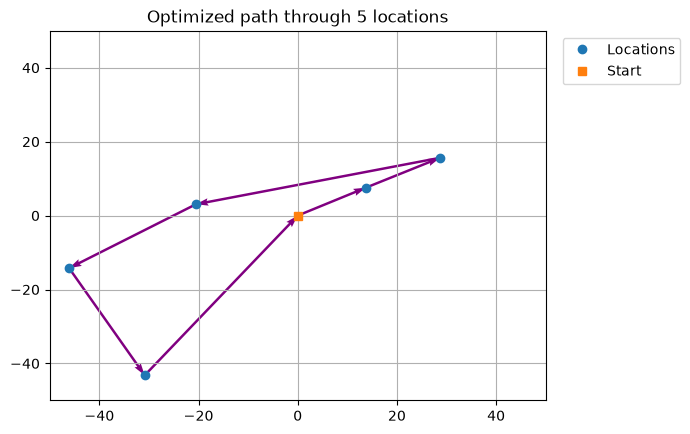

PASS


In [9]:
plot_path(random_locations, start_location, random_path, x_range, y_range)
check_path(random_path, start_location, random_locations)

## Hand Calculation Verification (Brute Force)

In [10]:
# Get all different path permutations and their distances
from itertools import permutations

t0 = time.perf_counter()
perms = np.array(list(permutations(random_locations)))  # every ordering of the locations
perms = [np.vstack([start_location, perm, start_location]) for perm in perms]
best_cost, best_order = np.inf, None

for i in range(len(perms)):
    cost = np.sum(np.linalg.norm(np.diff(perms[i], axis=0), axis=1))
    if cost < best_cost:
        best_cost, best_order = cost, i

brute_path = perms[best_order]
compute_time = time.perf_counter() - t0

print(f"Brute force took {compute_time:.4f} s for {len(random_locations)} locations")
print(f"Brute force path:\n{brute_path}")

# Throws assertion error if the paths are not equal (up to numerical precision)
try:
    np.testing.assert_allclose(brute_path, random_path, rtol=1e-5, atol=1e-8)
    print("PASS! Paths are equal.")
except AssertionError as e:
    # Reverse the order of the path and check again
    print("Paths are not equal, checking reversed order...")
    np.testing.assert_allclose(brute_path[::-1], random_path, rtol=1e-5, atol=1e-8)
    print("PASS! Paths are equal when reversed.")

Brute force took 0.0031 s for 5 locations
Brute force path:
[[  0.           0.        ]
 [ 13.7520896    7.56028938]
 [ 28.698546    15.63335218]
 [-20.53349973   3.05867556]
 [-46.09370838 -14.21863955]
 [-30.84792131 -43.20996418]
 [  0.           0.        ]]
PASS! Paths are equal.


# Collinear Target Test

In [11]:
x_range = 5 * n
y_scale = 0
x_offset = 0
collinear_locations = np.column_stack([
    x_range - 10 * n * np.arange(n+1) / n + x_offset,
    y_scale * np.ones(n+1)
])
print("Check collinear locations don't contain the start location, otherwise change x_offset value.")
print(collinear_locations)

Check collinear locations don't contain the start location, otherwise change x_offset value.
[[ 25.   0.]
 [ 15.   0.]
 [  5.   0.]
 [ -5.   0.]
 [-15.   0.]
 [-25.   0.]]


## Path Planning

In [12]:
t0 = time.perf_counter()
collinear_path = optimize_path(start_location, collinear_locations)
compute_time = time.perf_counter() - t0
print(f"optimize_path took {compute_time:.4f} s for {len(collinear_locations)} locations")

optimize_path took 0.0039 s for 6 locations


## Results

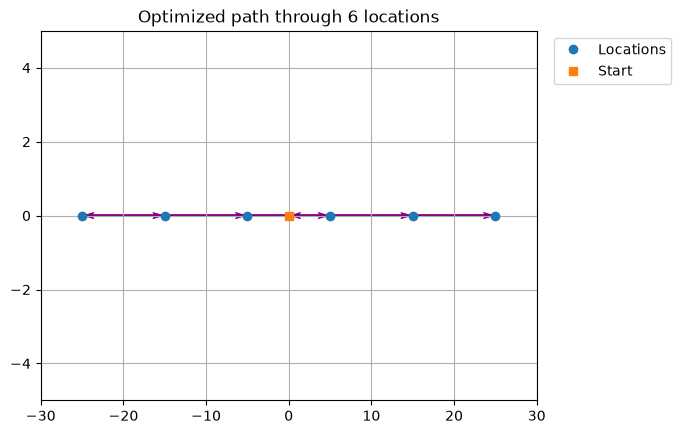

PASS


In [13]:
plot_path(collinear_locations, start_location, collinear_path, (-x_range - 5, x_range + 5), (y_scale - 5, y_scale + 5))
check_path(collinear_path, start_location, collinear_locations)

# Naive vs DP Comaprison Test

In [14]:
x_range = (-50, 50)
y_range = (-50, 50)
naive_locations = np.array([[-10, 42], [7, -33], [-4, -17], [-10, 27], [36, 12], [17, 26], [-18, -39], [21, 3], [42, -20], [13, -20]])

## Path Planning - Naive (Nearest Neighbor)

In [15]:
def nearest_neighbor_path(start_location: np.ndarray, locations: np.ndarray) -> np.ndarray:
    """Greedy path: from the current point, always go to the closest unvisited point, then return to start.

    Args:
        start_location (np.ndarray): The starting location.
        locations (np.ndarray): An array of shape (n, 2) containing the locations to visit.

    Returns:
        np.ndarray: An array of shape (n+2, 2) containing the locations in visit order, beginning and ending at the start location.
    """
    current = np.asarray(start_location, float)
    unvisited = list(np.asarray(locations, float))
    path = [current]

    while unvisited:
        # find the closest unvisited point
        dists = [np.linalg.norm(p - current) for p in unvisited]
        closest = unvisited.pop(int(np.argmin(dists)))
        path.append(closest)
        current = closest

    path.append(np.asarray(start_location, float))  # return home
    return np.array(path)

t0 = time.perf_counter()
naive_path = nearest_neighbor_path(start_location, naive_locations)
compute_time = time.perf_counter() - t0
print(f"nearest_neighbor_path took {compute_time:.4f} s for {len(naive_locations)} locations")

nearest_neighbor_path took 0.0020 s for 10 locations


## Path Planning - DP

In [16]:
t0 = time.perf_counter()
dp_path = optimize_path(start_location, naive_locations)
compute_time = time.perf_counter() - t0
print(f"optimize_path took {compute_time:.4f} s for {len(naive_locations)} locations")

optimize_path took 0.0048 s for 10 locations


## Results

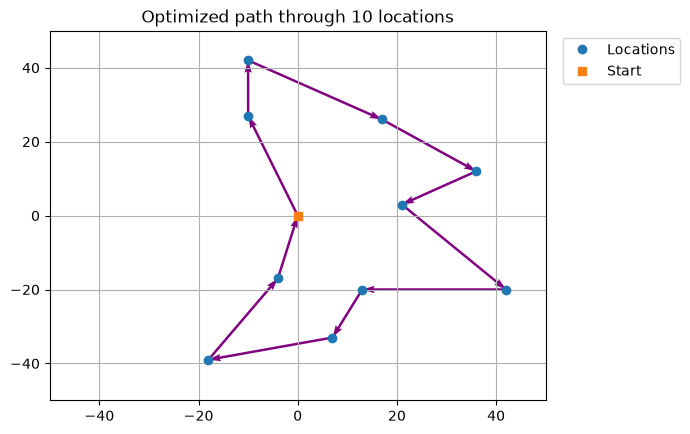

PASS


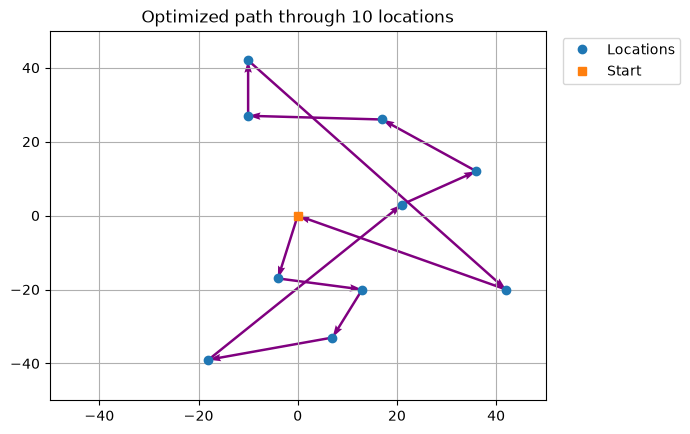

PASS


In [17]:
plot_path(naive_locations, start_location, dp_path, x_range, y_range)
check_path(dp_path, start_location, naive_locations)

plot_path(naive_locations, start_location, naive_path, x_range, y_range)
check_path(naive_path, start_location, naive_locations)

In [18]:
start = np.array([0, 0])
cost = lambda T: np.sum(np.linalg.norm(np.diff(T, axis=0), axis=1))
print(f"Cost of optimized path: {cost(dp_path):.4f}")
print(f"Cost of nearest neighbor path: {cost(naive_path):.4f}")

Cost of optimized path: 259.9844
Cost of nearest neighbor path: 342.6203


# Computation Time Aanalysis

## Finding the computation time distribution for optimize_path() for 10 locations over 1000 solves

In [19]:
n_locations = 10
x_range = (-50, 50)
y_range = (-50, 50)
min_distance = 5
start_location = [0, 0]
seed = 11
n_trials = 1000
times = []
for _ in range(n_trials):
    locs = sample_locations(n_locations, x_range, y_range, min_distance, start_location, seed)
    t0 = time.perf_counter()
    optimize_path(start_location, locs)
    times.append(time.perf_counter() - t0)
times = np.array(times)

mean = 0.0023 s, median = 0.0021 s, std = 0.0004 s, max = 0.0047 s


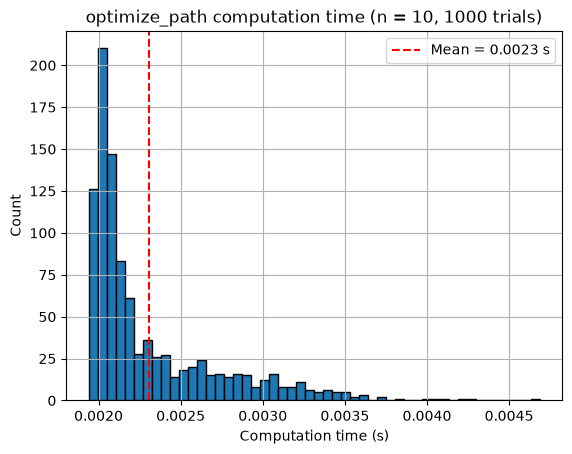

In [20]:
print(f"mean = {times.mean():.4f} s, median = {np.median(times):.4f} s, "
      f"std = {times.std():.4f} s, max = {times.max():.4f} s")

plt.figure()
plt.hist(times, bins=50, edgecolor='black')
plt.axvline(times.mean(), color='red', linestyle='--', label=f'Mean = {times.mean():.4f} s')
plt.xlabel('Computation time (s)')
plt.ylabel('Count')
plt.title(f'optimize_path computation time (n = {n_locations}, {n_trials} trials)')
plt.legend()
plt.grid()
plt.show()

# Trajectory Generation (Task 2, Milestone 1)

## Setup

In [21]:
from ae483.mytools import build_trajectory, check_trajectory, plot_trajectory

start_location = np.array([0., 0.])
x_range = (-1, 1)
y_range = (-1, 1)
min_distance = 0.5

t_hover = 1.
t_dropoff = 2.
z_safe = 0.5
z_dropoff = 0.2
v_max = 0.3

cases = [(2, 0), (3, 0), (3, 1), (4, 0), (4, 1)] # (n, seed)

## Plan, plot, and check each trajectory

n = 2, seed = 0, passed = True


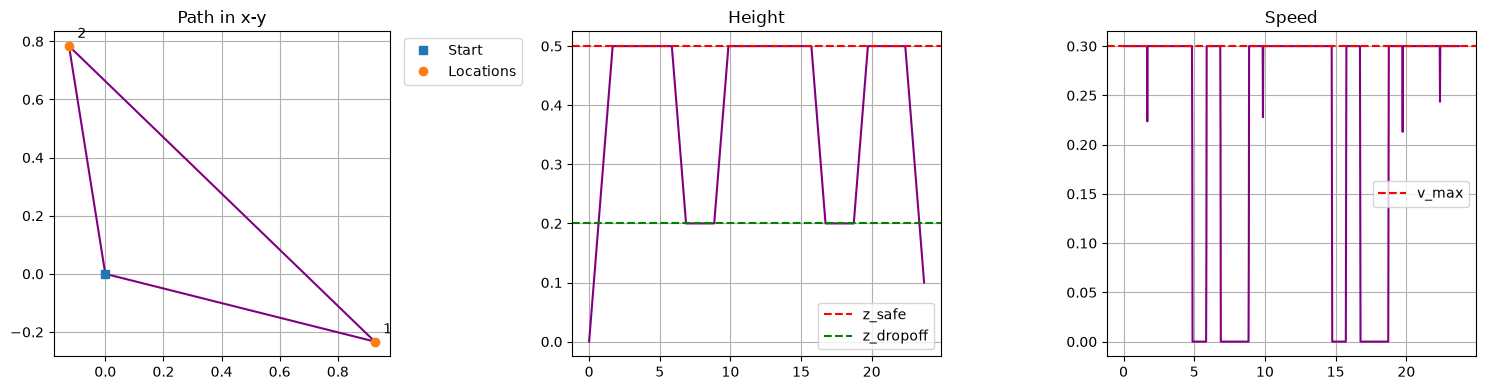

n = 3, seed = 0, passed = True


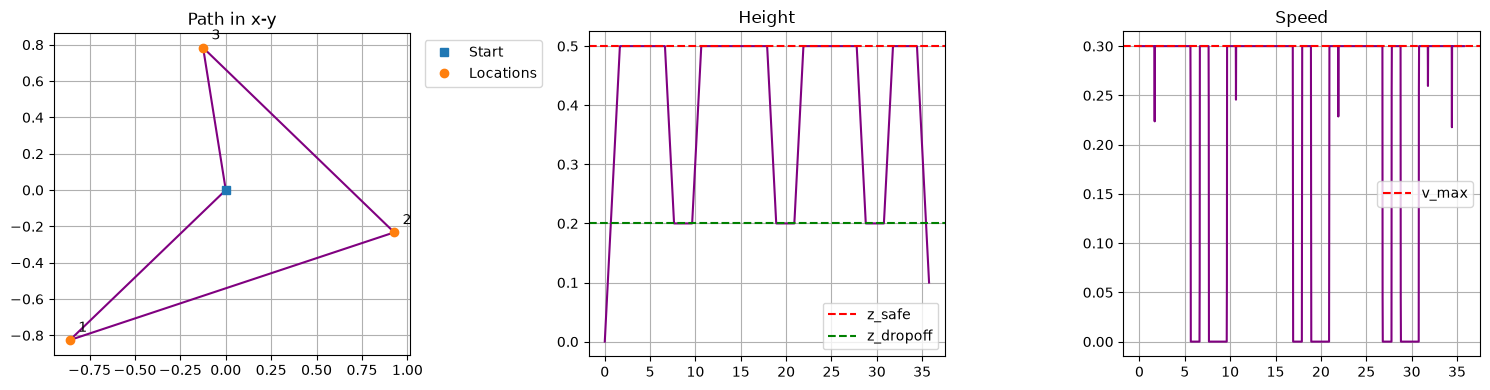

n = 3, seed = 1, passed = True


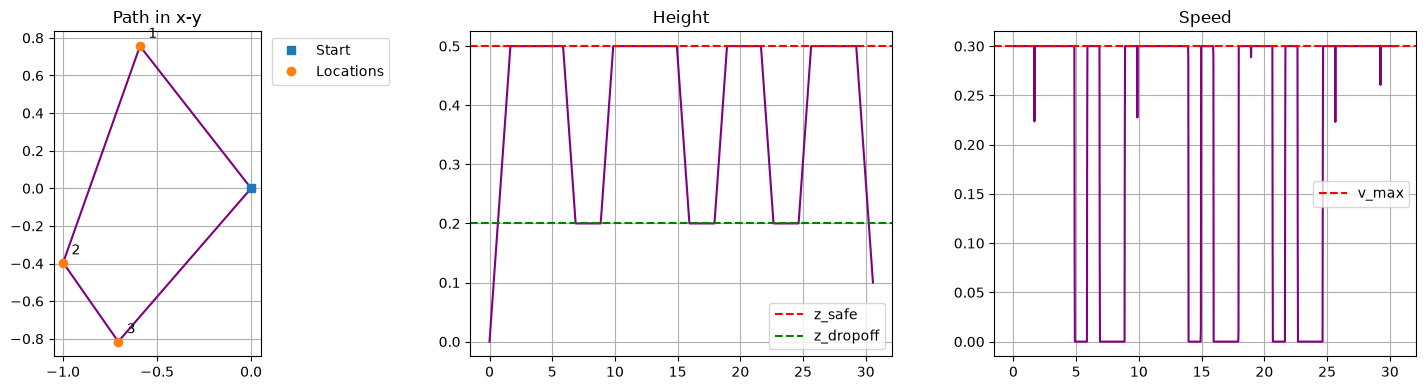

n = 4, seed = 0, passed = True


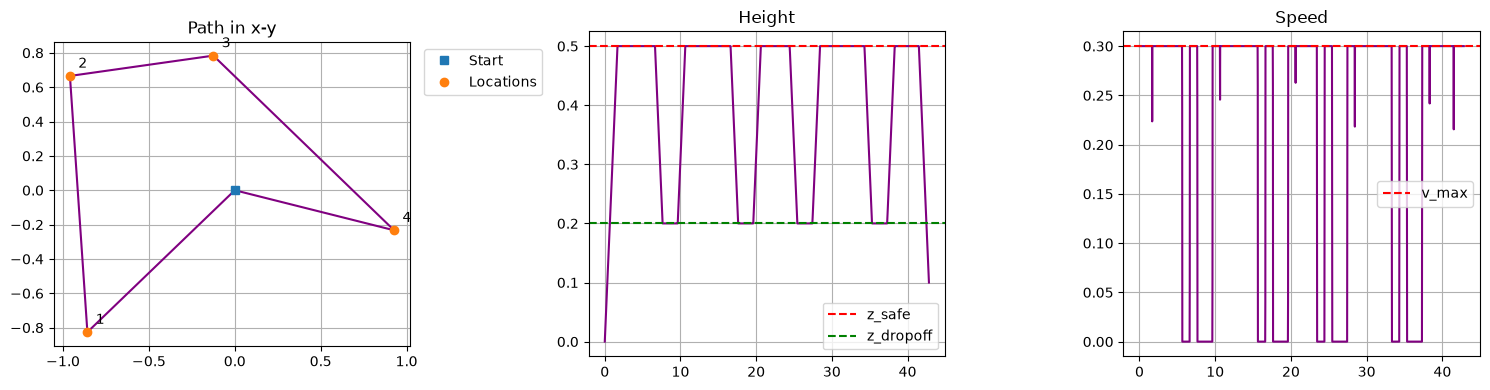

n = 4, seed = 1, passed = True


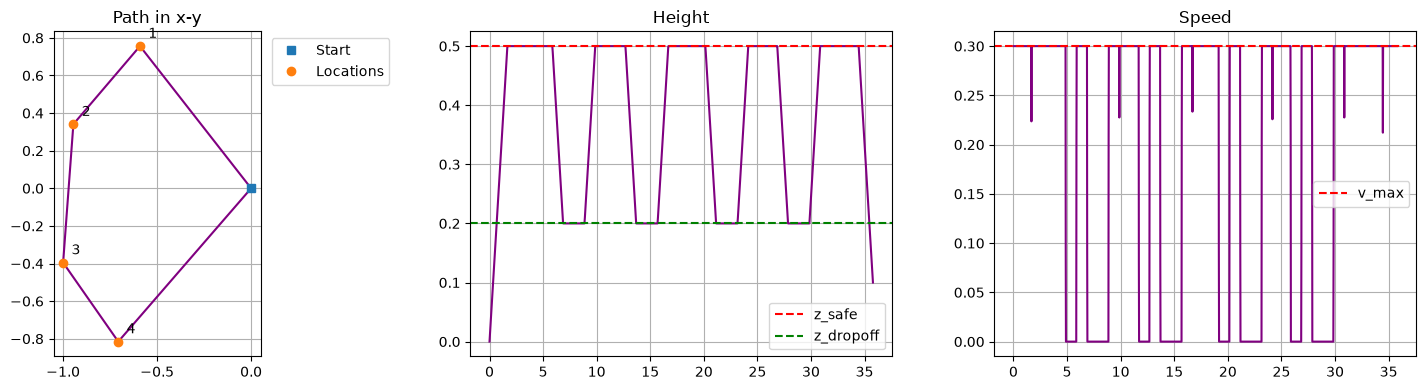

In [22]:
log = []
for n, seed in cases:
    locations = sample_locations(n, x_range, y_range, min_distance, start_location, seed)
    path = optimize_path(start_location, locations)
    t, x_des = build_trajectory(path, t_hover, t_dropoff, z_safe, z_dropoff, v_max)
    result = check_trajectory(path, t, x_des, v_max, z_safe, z_dropoff)

    print(f"n = {n}, seed = {seed}, passed = {result['passed']}")
    plot_trajectory(path, t, x_des, v_max, z_safe, z_dropoff)
    log.append([n, seed, t[-1], result['max_target_error'], result['max_speed'], result['min_z_moving'],
                result['order'], result['speed'], result['altitude']])

## Log

In [23]:
import csv

header = ['n', 'seed', 'duration_s', 'max_target_error_m', 'max_speed_mps', 'min_z_moving_m', 'order', 'speed', 'altitude']
with open('trajectory_log.csv', 'w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(header)
    writer.writerows(log)

print(f"{'n':>2} {'seed':>4} {'time (s)':>9} {'target err':>10} {'max v':>6} {'min z':>6}  order speed altitude")
for n, seed, T, err, v, z, order, speed, altitude in log:
    print(f"{n:>2} {seed:>4} {T:>9.1f} {err:>10.4f} {v:>6.3f} {z:>6.3f}  {order!s:>5} {speed!s:>5} {altitude!s:>8}")

 n seed  time (s) target err  max v  min z  order speed altitude
 2    0      23.7     0.0000  0.300  0.500   True  True     True
 3    0      35.8     0.0000  0.300  0.500   True  True     True
 3    1      30.6     0.0000  0.300  0.500   True  True     True
 4    0      42.8     0.0000  0.300  0.500   True  True     True
 4    1      35.8     0.0000  0.300  0.500   True  True     True
